In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset from Yahoo Finance
data = yf.download("AAPL", start="2015-01-01", end="2026-01-01", auto_adjust=False)

# Newer yfinance versions return multi-level columns, so flatten them
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

# Keep only the required columns and save a copy
data = data[["Open", "High", "Low", "Close", "Volume"]]
data.to_csv("stock_data.csv")

# Display first 5 rows
print(data.head())

# Display dataset information
print(data.info())

# Check missing values
print(data.isnull().sum())
data = data.ffill().dropna()

[*********************100%***********************]  1 of 1 completed

Price            Open       High        Low      Close     Volume
Date                                                             
2015-01-02  27.847500  27.860001  26.837500  27.332500  212818400
2015-01-05  27.072500  27.162500  26.352501  26.562500  257142000
2015-01-06  26.635000  26.857500  26.157499  26.565001  263188400
2015-01-07  26.799999  27.049999  26.674999  26.937500  160423600
2015-01-08  27.307501  28.037500  27.174999  27.972500  237458000
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2766 entries, 2015-01-02 to 2025-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2766 non-null   float64
 1   High    2766 non-null   float64
 2   Low     2766 non-null   float64
 3   Close   2766 non-null   float64
 4   Volume  2766 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 129.7 KB
None
Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


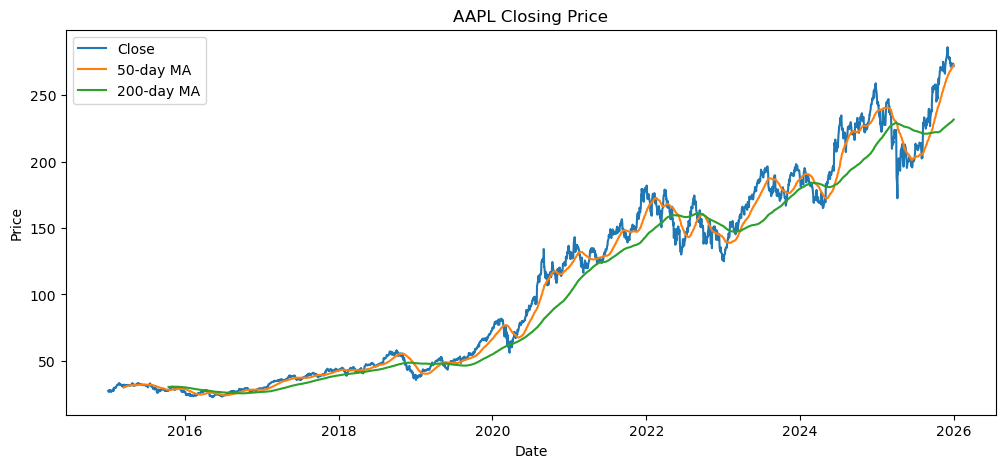

In [3]:
# Plot closing price with moving averages
plt.figure(figsize=(12, 5))
plt.plot(data["Close"], label="Close")
plt.plot(data["Close"].rolling(50).mean(), label="50-day MA")
plt.plot(data["Close"].rolling(200).mean(), label="200-day MA")
plt.title("AAPL Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

In [4]:
# Use previous day's values to predict today's closing price
feature_names = ["Open", "High", "Low", "Close", "Volume"]
X = data[feature_names].shift(1)
y = data["Close"]

In [5]:
# Remove the first row (it has no previous day)
X = X.iloc[1:]
y = y.iloc[1:]

In [6]:
# Split data into training and testing (no shuffle, because it is time-series data)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

# Standardize the data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)
# Display results
print("Linear Regression \nMAE:", lr_mae, "\nRMSE:", lr_rmse, "\nR2:", lr_r2)

Linear Regression 
MAE: 2.434638060587285 
RMSE: 3.600499601017279 
R2: 0.9848012964857046


In [8]:
# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)
print("Random Forest     \nMAE:", rf_mae, "\nRMSE:", rf_rmse, "\nR2:", rf_r2)


Random Forest     
MAE: 26.170920040965296 
RMSE: 35.55080992740345 
R2: -0.48176730421838787


In [9]:
# Function to draw the 3 standard plots for one model
def plot_model(name, y_test, y_pred, color):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Actual vs predicted over time
    axes[0].plot(y_test.index, y_test.values, label="Actual", color="black")
    axes[0].plot(y_test.index, y_pred, label="Predicted", color=color)
    axes[0].set_title(name + ": Actual vs Predicted Price")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel("Price")
    axes[0].legend()
    axes[0].tick_params(axis="x", rotation=30)
    # 2. Scatter plot (points close to the red line = good predictions)
    axes[1].scatter(y_test, y_pred, alpha=0.5, color=color)
    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())
    axes[1].plot([low, high], [low, high], color="red", linestyle="--")
    axes[1].set_title(name + ": Actual vs Predicted (Scatter)")
    axes[1].set_xlabel("Actual Price")
    axes[1].set_ylabel("Predicted Price")
     # 3. Error (residual) distribution
    errors = y_test.values - y_pred
    axes[2].hist(errors, bins=40, color=color, edgecolor="black")
    axes[2].axvline(0, color="red", linestyle="--")
    axes[2].set_title(name + ": Prediction Error Distribution")
    axes[2].set_xlabel("Error (Actual - Predicted)")
    axes[2].set_ylabel("Count")
    plt.show()

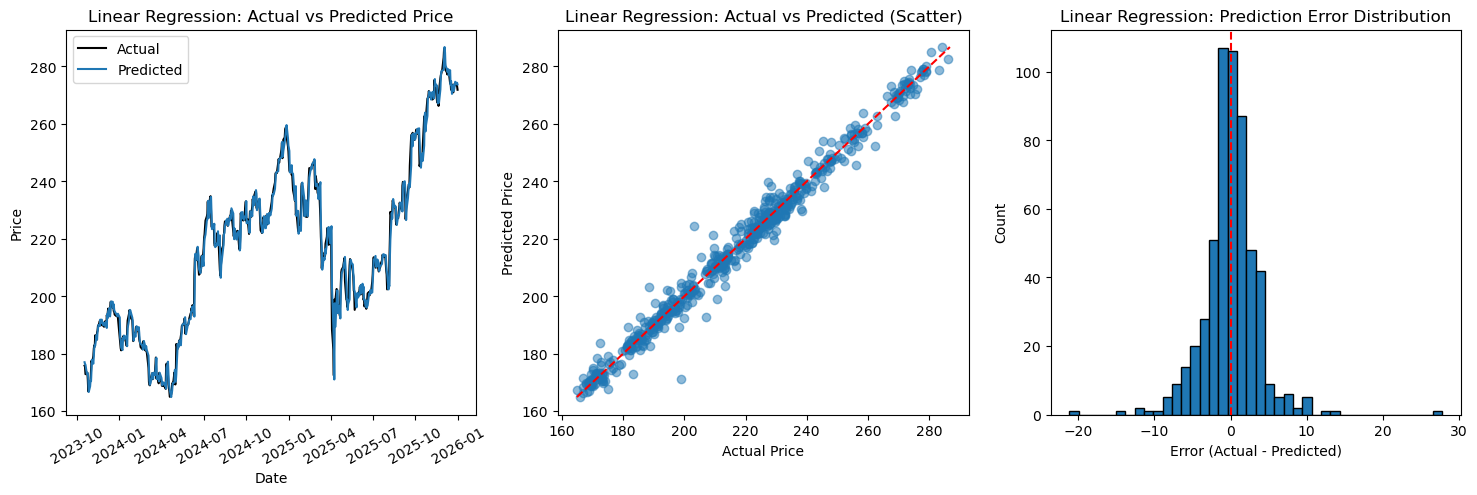

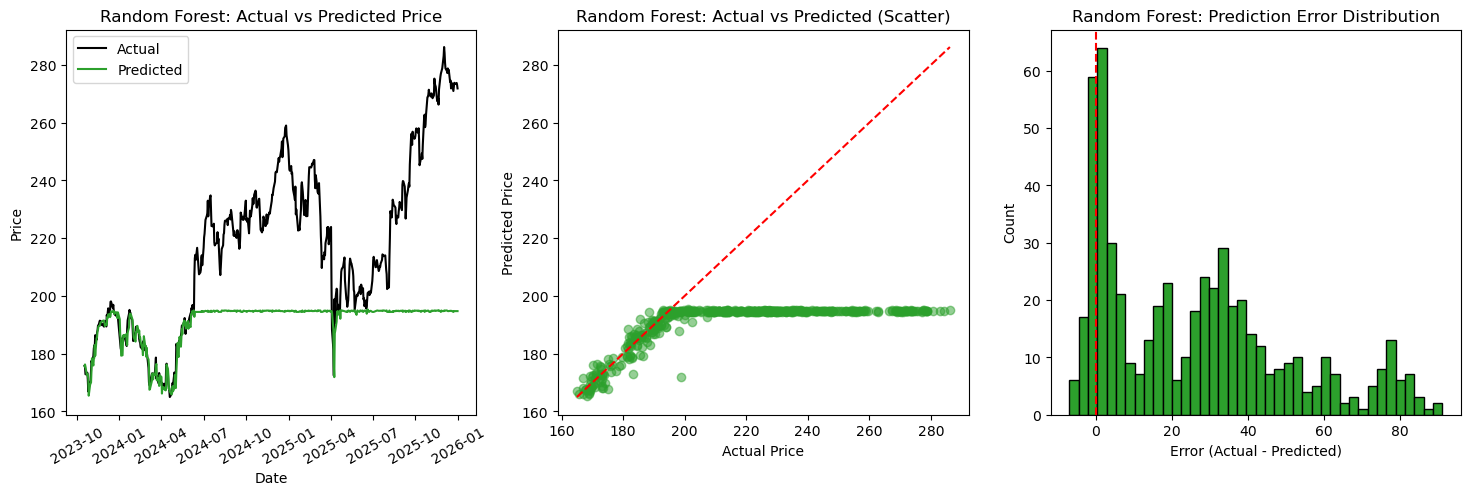

In [10]:
# Plots for Linear Regression
plot_model("Linear Regression", y_test, lr_pred, "tab:blue")
# Plots for Random Forest
plot_model("Random Forest", y_test, rf_pred, "tab:green")

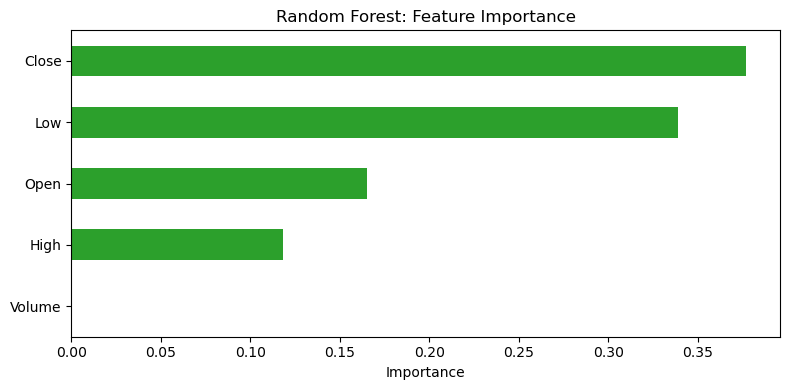

In [11]:
# Random Forest feature importance
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
plt.figure(figsize=(8, 4))
importance.plot(kind="barh", color="tab:green")
plt.title("Random Forest: Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()

plt.show()

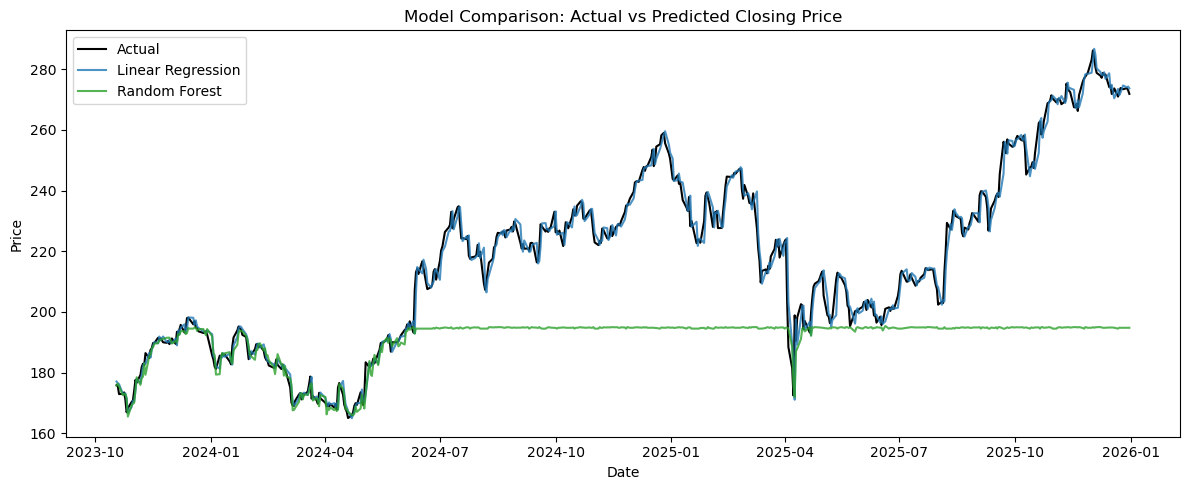

In [12]:
# Both models together on one plot
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label="Actual", color="black")
plt.plot(y_test.index, lr_pred, label="Linear Regression", color="tab:blue", alpha=0.8)
plt.plot(y_test.index, rf_pred, label="Random Forest", color="tab:green", alpha=0.8)
plt.title("Model Comparison: Actual vs Predicted Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.tight_layout()

plt.show()

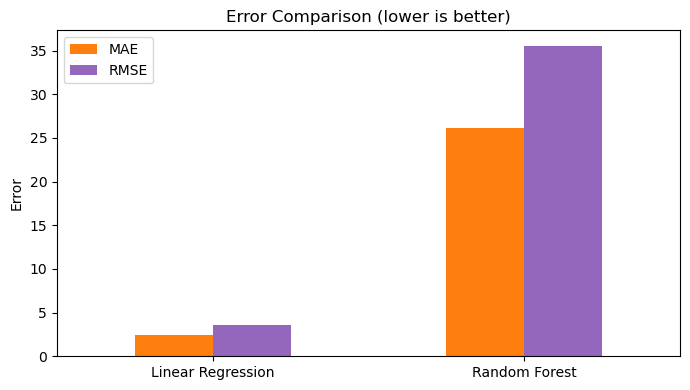

In [13]:

# Bar chart comparing error metrics
metrics = pd.DataFrame(
    {"MAE": [lr_mae, rf_mae], "RMSE": [lr_rmse, rf_rmse]},
    index=["Linear Regression", "Random Forest"],
)
metrics.plot(kind="bar", figsize=(7, 4), color=["tab:orange", "tab:purple"])
plt.title("Error Comparison (lower is better)")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:

# Column names used for prediction
feature_names = ["Open", "High", "Low", "Close", "Volume"]

# Function to predict the next closing price
def predict_new(open_price, high, low, close, volume):

    # Store the input values in a table
    new_data = pd.DataFrame(
        [[open_price, high, low, close, volume]],
        columns=feature_names
    )

    # Convert input values into the format used during training
    new_scaled = scaler.transform(new_data)

    # Predict using Linear Regression
    lr_price = lr.predict(new_scaled)[0]

    # Predict using Random Forest
    rf_price = rf.predict(new_scaled)[0]

    # Display the results
    print("Input closing price:", close)
    print("Linear Regression prediction:", round(lr_price, 2))
    print("Random Forest prediction:", round(rf_price, 2))


# Give sample stock values
prediction=predict_new(250, 255, 248, 253, 50000000)
if prediction == 1:
    print("Customer is likely to leave the bank (Churn).")
else:
    print("Customer is likely to stay with the bank.")

Input closing price: 253
Linear Regression prediction: 252.97
Random Forest prediction: 194.81
Customer is likely to stay with the bank.
